# Conditional workflow in LangGraph

In [16]:
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv
from typing import TypedDict, Annotated, List
import operator

In [17]:
# sentiment class
class SentimentState(TypedDict):

    user_input: str
    sentiment:str
    response: str

In [18]:
def analyzerr_sentiment1(state: SentimentState) -> SentimentState:

    input = state['user_input']

    if 'good' in input or 'happy' in input:
        sentiment = state['sentiment']
        return state
    else:
        'negative' in input
        sentiment = state['sentiment']
        return state

In [ ]:
def analyze_sentiment(state: SentimentState):
    
    text = state["user_input"].lower()
    if "good" in text or "happy" in text:
        return {"sentiment": "positive"}
    else:
        return {"sentiment": "negative"}

def cheerful_node(state: SentimentState):
    return {"response": "That's wonderful! Keep up the great energy!"}

def supportive_node(state: SentimentState):
    return {"response": "I'm sorry to hear that. I'm here for you!"}

In [22]:
# router
def router(state: SentimentState):

    if state['sentiment'] == 'positive':
        return 'happy_path'
    else:
        return 'sad_path'

In [23]:
# build the graph

# initialize the graph
graph = StateGraph(SentimentState)

# add the node
graph.add_node('analyzer', analyze_sentiment)
graph.add_node('cheerful', cheerful_node)
graph.add_node('supportive', supportive_node)

# add the edge
graph.add_edge(START, 'analyzer')

# conditional edge
graph.add_conditional_edges('analyzer', router,
                           {'happy_path': 'cheerful', 
                            'sad_path': 'supportive'
                           }
                          )

graph.add_edge('cheerful', END)
graph.add_edge('supportive', END)

In [24]:
workflow = graph.compile()

In [25]:
# prepare the input as dictionary

initial_input = {'user_input': 'I am feeling sad'}

result = workflow.invoke(initial_input)

print(f'Sentiment Detected: {result['sentiment']}')

print(f'Assistent response: {result['response']}')

Sentiment Detected: negative
Assistent response: I'm sorry to hear that. I'm here for you!


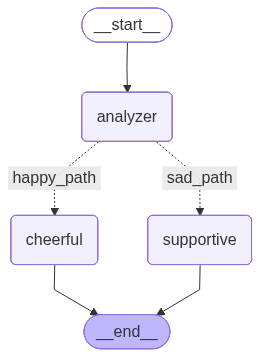

In [28]:
from IPython.display import Image, display

# This will display the graph directly in a Jupyter Notebook or Google Colab
try:
    display(Image(workflow.get_graph().draw_mermaid_png()))
except Exception:
    # This requires some extra dependencies (like pygraphviz or mermaid.ink)
    print("Could not render image. Try printing the Mermaid string instead.")